<p align="center">
  <img src="https://readme-typing-svg.herokuapp.com?font=Fira+Code&size=28&duration=3000&pause=1200&color=00F5FF&center=true&vCenter=true&width=700&lines=+Name+-+Satyam+Chandra;" alt="Typing SVG" />
</p>

<div style="background-color: #f8f9fa; padding: 25px; border-radius: 12px; border-left: 6px solid #4a90e2; box-shadow: 0 4px 6px rgba(0,0,0,0.05); font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; transition: transform 0.3s ease-in-out;" onmouseover="this.style.transform='translateY(-5px)'" onmouseout="this.style.transform='translateY(0)'">
    <h2 style="margin: 0; color: #2c3e50; font-size: 28px;">Satyam Chandra</h2>
    <p style="margin: 5px 0 20px 0; color: #7f8c8d; font-size: 16px; font-style: italic;">AI & ML Developer</p>
    <div style="display: flex; gap: 15px; flex-wrap: wrap;">
        <a href="https://satyamchandra-info.vercel.app/" target="_blank" style="text-decoration: none; color: white; background-color: #1abc9c; padding: 8px 16px; border-radius: 6px; font-weight: 600; font-size: 14px; box-shadow: 0 2px 4px rgba(26,188,156,0.3);">🌐 Portfolio</a>
        <a href="https://github.com/C0DER-B0T" target="_blank" style="text-decoration: none; color: white; background-color: #34495e; padding: 8px 16px; border-radius: 6px; font-weight: 600; font-size: 14px; box-shadow: 0 2px 4px rgba(52,73,94,0.3);">🐙 GitHub</a>
        <a href="https://www.linkedin.com/in/satyam-chandra-953857356/" target="_blank" style="text-decoration: none; color: white; background-color: #0077b5; padding: 8px 16px; border-radius: 6px; font-weight: 600; font-size: 14px; box-shadow: 0 2px 4px rgba(0,119,181,0.3);">💼 LinkedIn</a>
        <a href="mailto:chandrasatyam31@gmail.com" style="text-decoration: none; color: white; background-color: #e74c3c; padding: 8px 16px; border-radius: 6px; font-weight: 600; font-size: 14px; box-shadow: 0 2px 4px rgba(231,76,60,0.3);">✉️ Email</a>
    </div>
</div>

<center>
<h1>Module 4: Introduction to Fully Connected NN - Assignment</h1>
<h3>Task: Fashion MNIST Image Classification</h3>
<hr>

### Step 1: Imports and Data Loading

In [1]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt
import pandas as pd

# Load Fashion MNIST
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


### Step 2: Data Visualization

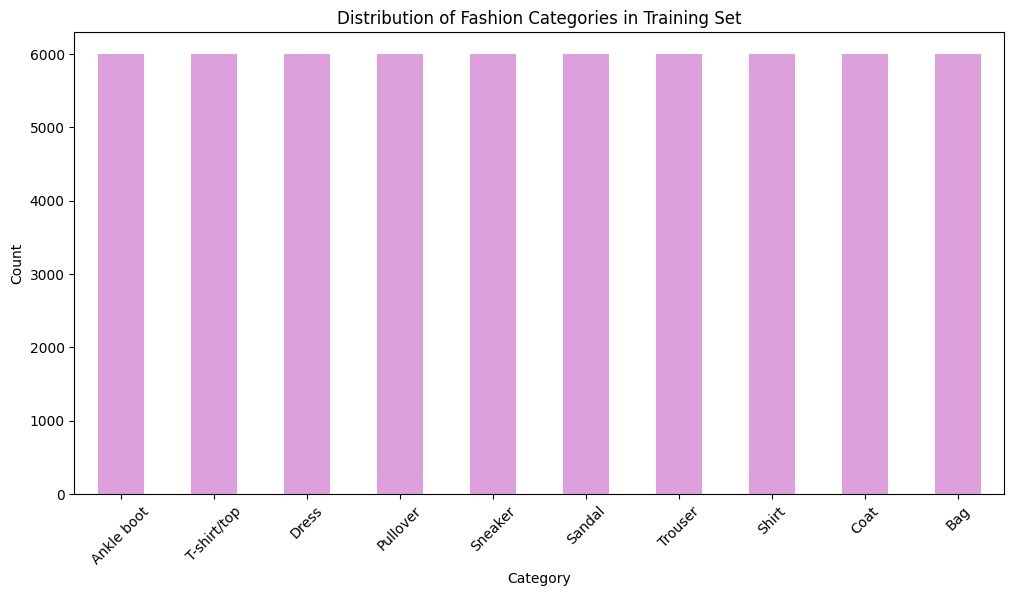

In [2]:
# Visualize the distribution of fashion items
plt.figure(figsize=(12, 6))
y_series = pd.Series(y_train).map(lambda x: class_names[x])
y_series.value_counts().plot(kind='bar', color='plum')
plt.title('Distribution of Fashion Categories in Training Set')
plt.xlabel('Category')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()

### Step 3: Data Preprocessing

In [3]:
# Normalize pixel values
X_train, X_test = X_train / 255.0, X_test / 255.0

# One-Hot Encoding labels
y_train_cat = to_categorical(y_train)
y_test_cat = to_categorical(y_test)

print(f"Preprocessed Training Data Shape: {X_train.shape}")

Preprocessed Training Data Shape: (60000, 28, 28)


### Step 4: Model Architecture (FCNN)

In [4]:
model = Sequential([
    Flatten(input_shape=(28, 28)), # Input layer
    Dense(512, activation='relu'), # Hidden Layer 1
    Dense(256, activation='relu'), # Hidden Layer 2
    Dense(10, activation='softmax') # Output Layer
])

model.compile(optimizer='sgd',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 535,818 (2.04 MB)

 Trainable params: 535,818 (2.04 MB)

 Non-trainable params: 0 (0.00 B)

### Step 5: Training and Evaluation Plan

In [7]:

history = model.fit(X_train, y_train_cat, epochs=15, validation_split=0.2, batch_size=64, verbose=1)

Epoch 1/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 25s 30ms/step - accuracy: 0.7329 - loss: 0.8577 - val_accuracy: 0.7952 - val_loss: 0.6009
Epoch 2/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 25s 33ms/step - accuracy: 0.8153 - loss: 0.5515 - val_accuracy: 0.8188 - val_loss: 0.5250
Epoch 3/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 46s 40ms/step - accuracy: 0.8310 - loss: 0.4931 - val_accuracy: 0.8293 - val_loss: 0.4836
Epoch 4/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 43s 42ms/step - accuracy: 0.8409 - loss: 0.4621 - val_accuracy: 0.8435 - val_loss: 0.4524
Epoch 5/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.8478 - loss: 0.4416 - val_accuracy: 0.8460 - val_loss: 0.4487
Epoch 6/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 44s 58ms/step - accuracy: 0.8544 - loss: 0.4242 - val_accuracy: 0.8543 - val_loss: 0.4195
Epoch 7/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 37s 49ms/step - accuracy: 0.8580 - loss: 0.4098 - val_accuracy: 0.8575 - val_loss: 0.4086
Epoch 8/15
750/750 ━━━━━━━━━━━━━━━━━━━━ 32s 42ms/step - accuracy: 0.8597 - loss: 0.4002 - 